# GAN HOMEWORK: VANILLA GAN → cGAN → PATCHGAN & FEATURE MATCHING

**A GAN = two networks playing a game:**
- **Generator (G):** random noise `z` → fake image. Goal: **fool D**.
- **Discriminator (D):** image → "real or fake?". Goal: **catch G**.

They train **in turns**. As D gets better at spotting fakes, G is forced to make more realistic images.

## 0. SETUP
Imports, **seed 42**, Mac GPU, and the number of training epochs for every GAN.

In [1]:
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch import nn

torch.manual_seed(42)
device = 'mps' if torch.backends.mps.is_available() else 'cpu'
EPOCHS = 20          # training epochs for every GAN in this notebook
NOISE = 64           # size of the random noise vector z
print('device:', device)

device: mps


## 1. LOAD MNIST + FASHION-MNIST (WITH LABELS)
Same loader as before. Pixels are scaled to **[−1, 1]** (not 0–1) because the generator ends with **tanh**, which outputs −1…1. Real and fake images must be on the same scale.
Labels are needed for the **conditional GAN** in Part 2.

In [2]:
def load_images(path):
    raw = open(path, 'rb').read()
    n, rows, cols = (int.from_bytes(raw[i:i + 4], 'big') for i in (4, 8, 12))
    return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, rows, cols)

def load_labels(path):
    return np.frombuffer(open(path, 'rb').read(), dtype=np.uint8, offset=8)

def to_tensor(images):
    # (N, 28, 28) 0..255  ->  (N, 1, 28, 28) -1..1
    return torch.from_numpy(images.copy()).float().div(255).mul(2).sub(1).unsqueeze(1)

def to_labels(labels):
    return torch.from_numpy(labels.astype(np.int64))

M, FA = '../CV/archive', '../CV/fashion'
mnist = {'x': to_tensor(load_images(f'{M}/train-images.idx3-ubyte')),  'y': to_labels(load_labels(f'{M}/train-labels.idx1-ubyte')),
         'test_x': to_tensor(load_images(f'{M}/t10k-images.idx3-ubyte')), 'test_y': to_labels(load_labels(f'{M}/t10k-labels.idx1-ubyte')),
         'classes': [str(i) for i in range(10)]}
fashion = {'x': to_tensor(load_images(f'{FA}/train-images-idx3-ubyte')),  'y': to_labels(load_labels(f'{FA}/train-labels-idx1-ubyte')),
           'test_x': to_tensor(load_images(f'{FA}/t10k-images-idx3-ubyte')), 'test_y': to_labels(load_labels(f'{FA}/t10k-labels-idx1-ubyte')),
           'classes': ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']}

print('train', mnist['x'].shape, ' test', mnist['test_x'].shape, ' pixel range', mnist['x'].min().item(), '...', mnist['x'].max().item())

train torch.Size([60000, 1, 28, 28])  test torch.Size([10000, 1, 28, 28])  pixel range -1.0 ... 1.0


## 2. HELPER: SHOW MANY IMAGES IN ONE GRID
Converts −1…1 back to 0…1 for display.

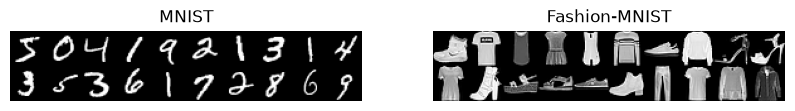

In [3]:
def show_grid(images, nrow, ax, title=''):
    images = (images.detach().cpu()[:, 0] + 1) / 2                  # -1..1 -> 0..1
    ncol = len(images) // nrow
    rows = [torch.cat(list(images[r * ncol:(r + 1) * ncol]), dim=1) for r in range(nrow)]
    ax.imshow(torch.cat(rows, dim=0), cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
show_grid(mnist['x'][:20], 2, axes[0], 'MNIST')
show_grid(fashion['x'][:20], 2, axes[1], 'Fashion-MNIST')
plt.show()

## 3. GENERATOR: NOISE z → IMAGE
Like the VAE decoder: `Linear → (128, 7, 7) → ConvTranspose → (64, 14, 14) → ConvTranspose → (1, 28, 28) → tanh`.
- **BatchNorm** keeps activations well-scaled, which makes GAN training much more stable (DCGAN recipe).
- **n_classes > 0 → conditional:** the class label is turned into a small vector (embedding) and **glued to z**, so G knows *what* to draw.

In [4]:
class Generator(nn.Module):
    def __init__(self, n_classes=0):
        super().__init__()
        self.n_classes = n_classes
        if n_classes:
            self.label_embedding = nn.Embedding(n_classes, n_classes)   # label -> 10 learned numbers
        self.net = nn.Sequential(
            nn.Linear(NOISE + n_classes, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7), nn.ReLU(),
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),                       # -> (64, 14, 14)
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),                         # -> (1, 28, 28)
            nn.Tanh(),                                                  # pixels in -1..1
        )

    def forward(self, z, labels=None):
        if self.n_classes:
            z = torch.cat([z, self.label_embedding(labels)], dim=1)     # noise + "what to draw"
        return self.net(z)


G = Generator()
print('noise', (4, NOISE), '-> image', G(torch.randn(4, NOISE)).shape)

noise (4, 64) -> image torch.Size([4, 1, 28, 28])


## 4. DISCRIMINATOR: IMAGE → "REAL OR FAKE?"
Like the conv encoder: `(1, 28, 28) → (64, 14, 14) → (128, 7, 7)` = **features**, then a head that outputs a **logit** (> 0 = "real", < 0 = "fake").
Two switches, used later:
- **n_classes > 0 → conditional:** the label becomes an extra 28×28 image channel, so D judges **"is this a real *7*?"**.
- **patch=True → PatchGAN:** instead of **one** verdict for the whole image, a **7×7 grid of verdicts**, each judging one local patch (≈ 18×18 pixels).

It also returns the **features**, needed for feature matching (Part 3).

In [5]:
class Discriminator(nn.Module):
    def __init__(self, n_classes=0, patch=False):
        super().__init__()
        self.n_classes = n_classes
        if n_classes:
            self.label_map = nn.Embedding(n_classes, 28 * 28)              # label -> one 28x28 "image"
        self.features = nn.Sequential(
            nn.Conv2d(2 if n_classes else 1, 64, 4, 2, 1),                # -> (64, 14, 14)
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1),                                  # -> (128, 7, 7)
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
        )
        if patch:
            self.head = nn.Conv2d(128, 1, 3, 1, 1)                        # -> (1, 7, 7): one verdict per patch
        else:
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 7 * 7, 1))   # -> one verdict per image

    def forward(self, x, labels=None):
        if self.n_classes:
            x = torch.cat([x, self.label_map(labels).view(-1, 1, 28, 28)], dim=1)
        f = self.features(x)
        return self.head(f), f                                            # logits, features


x = torch.randn(4, 1, 28, 28)
print('normal D :', Discriminator()(x)[0].shape)
print('PatchGAN :', Discriminator(patch=True)(x)[0].shape)

normal D : torch.Size([4, 1])
PatchGAN : torch.Size([4, 1, 7, 7])


## 5. TRAINING LOOP: D AND G TAKE TURNS
Every batch:
1. **D step:** real images → target **1**, fake images → target **0**. Loss = BCE. (`fake.detach()`, so G is not updated here.)
2. **G step:** push D's verdict on the fakes toward **1** ("make D believe they're real").
   With **feature_matching=True**: instead, make the **average D-features of fakes ≈ those of real images**.

Recorded every step: **D loss, G loss, D(real), D(fake)** (D's average "probability real").
A **fixed noise batch** is drawn at a few epochs, so we can watch the *same* z evolve and spot **mode collapse** (all samples looking alike).
Adam with **lr 2e-4, β1 = 0.5** is the standard, stable GAN setting.

In [6]:
bce = nn.BCEWithLogitsLoss()


@torch.no_grad()
def generate(G, z, labels=None):
    G.eval()
    images = G(z, labels).cpu()
    G.train()
    return images


def train_gan(G, D, data, epochs=EPOCHS, feature_matching=False, snapshot_epochs=(1, 2, 5, 10)):
    G.to(device); D.to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(data['x'], data['y']),
                                         batch_size=128, shuffle=True, drop_last=True)
    conditional = G.n_classes > 0
    fixed_z = torch.randn(100, NOISE, device=device)                      # the SAME noise at every snapshot
    fixed_labels = torch.arange(10, device=device).repeat_interleave(10)  # row r = class r (cGAN only)
    log = {'d_loss': [], 'g_loss': [], 'd_real': [], 'd_fake': []}
    snapshots = {}

    for epoch in range(1, epochs + 1):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            labels = y if conditional else None
            fake = G(torch.randn(len(x), NOISE, device=device), labels)

            # 1) Discriminator step: real -> 1, fake -> 0
            real_logits, _ = D(x, labels)
            fake_logits, _ = D(fake.detach(), labels)
            d_loss = bce(real_logits, torch.ones_like(real_logits)) + bce(fake_logits, torch.zeros_like(fake_logits))
            opt_D.zero_grad(); d_loss.backward(); opt_D.step()

            # 2) Generator step: fool D
            fake_logits, fake_features = D(fake, labels)
            if feature_matching:
                with torch.no_grad():
                    _, real_features = D(x, labels)
                g_loss = F.mse_loss(fake_features.mean(dim=0), real_features.mean(dim=0))   # match average features
            else:
                g_loss = bce(fake_logits, torch.ones_like(fake_logits))                    # "say these are real"
            opt_G.zero_grad(); g_loss.backward(); opt_G.step()

            log['d_loss'].append(d_loss.item())
            log['g_loss'].append(g_loss.item())
            log['d_real'].append(torch.sigmoid(real_logits).mean().item())
            log['d_fake'].append(torch.sigmoid(fake_logits).mean().item())

        if epoch in snapshot_epochs or epoch == epochs:
            snapshots[epoch] = generate(G, fixed_z, fixed_labels if conditional else None)
        if epoch == 1 or epoch % 5 == 0:
            n = len(loader)
            print(f"epoch {epoch:2d}   D loss {np.mean(log['d_loss'][-n:]):.3f}   G loss {np.mean(log['g_loss'][-n:]):.3f}   "
                  f"D(real) {np.mean(log['d_real'][-n:]):.2f}   D(fake) {np.mean(log['d_fake'][-n:]):.2f}")
    return log, snapshots

## 6. A "JUDGE" TO MEASURE QUALITY AND MODE COLLAPSE
GANs have no likelihood, so we judge the **pictures** with a small classifier trained on **real** data. On 5,000 generated images:
- **class coverage** (0–1): are **all 10 classes** generated equally often? **1 = perfect, low = mode collapse**.
- **confidence**: how sure the judge is about the class, i.e. **does it look like a clear object**? (real test data ≈ its value on real images)
- **diversity**: average distance between images **of the same class**, divided by the same for real images. **≈ 1 = as varied as real data, ≪ 1 = copies of each other**.
- **label accuracy** (cGAN only): does the image show the **class we asked for**?

In [7]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),      # -> (32, 14, 14)
            nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),     # -> (64, 7, 7)
            nn.Flatten(), nn.Linear(64 * 7 * 7, 10),
        )

    def forward(self, x):
        return self.net(x)


def train_judge(data, epochs=3):
    torch.manual_seed(42)
    clf = Classifier().to(device)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(data['x'], data['y']), batch_size=128, shuffle=True)
    for _ in range(epochs):
        for x, y in loader:
            loss = F.cross_entropy(clf(x.to(device)), y.to(device))
            opt.zero_grad(); loss.backward(); opt.step()
    clf.eval()
    with torch.no_grad():
        acc = (clf(data['test_x'].to(device)).argmax(1).cpu() == data['test_y']).float().mean().item()
    return clf, acc


def within_class_distance(images, labels, per_class=300):
    # average pixel distance between two images of the same class
    flat, dists = images.flatten(1), []
    for c in range(10):
        group = flat[labels == c][:per_class]
        if len(group) > 1:
            dists.append(torch.cdist(group, group).sum() / (len(group) * (len(group) - 1)))
    return torch.stack(dists).mean().item()


@torch.no_grad()
def judge(images, data, requested=None):
    clf = data['judge']
    probs = torch.cat([F.softmax(clf(b.to(device)), dim=1).cpu() for b in images.split(1000)])
    pred = probs.argmax(1)
    share = torch.bincount(pred, minlength=10).float() / len(pred)
    entropy = -(share[share > 0] * share[share > 0].log()).sum().item()
    labels = requested if requested is not None else pred
    result = {'class coverage': entropy / math.log(10),
              'confidence': probs.max(1).values.mean().item(),
              'diversity': within_class_distance(images, labels) / data['real_distance']}
    if requested is not None:
        result['label accuracy'] = (pred == requested).float().mean().item()
    return result, share


for name, data in [('MNIST', mnist), ('Fashion', fashion)]:
    data['judge'], acc = train_judge(data)
    data['real_distance'] = within_class_distance(data['test_x'], data['test_y'])
    real_scores, _ = judge(data['test_x'][:5000], data, requested=data['test_y'][:5000])
    data['real_scores'] = real_scores
    print(f'{name:8s} judge test accuracy {acc:.3f}   |   real test images:',
          {k: round(v, 3) for k, v in real_scores.items()})

MNIST    judge test accuracy 0.988   |   real test images: {'class coverage': 0.999, 'confidence': 0.981, 'diversity': 1.0, 'label accuracy': 0.983}


Fashion  judge test accuracy 0.896   |   real test images: {'class coverage': 0.995, 'confidence': 0.9, 'diversity': 1.0, 'label accuracy': 0.896}


## 7. HELPERS: PLOT TRAINING CURVES, PROGRESS AND SCORES
- **Losses** are smoothed over 100 steps (raw GAN losses are very noisy).
- **D(real) / D(fake):** in a healthy game they stay **between 0 and 1** (often around 0.6 / 0.3). D(fake) → 0 for good = **D wins, G gets no signal**; both → 0.5 = **D can't tell**.

In [8]:
def smooth(values, window=100):
    return np.convolve(values, np.ones(window) / window, mode='valid')


def plot_training(logs, title):
    # logs: {run name: log}
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
    for name, log in logs.items():
        steps_per_epoch = len(log['d_loss']) / EPOCHS
        epochs = np.arange(len(smooth(log['d_loss']))) / steps_per_epoch
        axes[0].plot(epochs, smooth(log['d_loss']), label=name)
        axes[1].plot(epochs, smooth(log['g_loss']), label=name)
        line, = axes[2].plot(epochs, smooth(log['d_real']), label=f'{name}: D(real)')
        axes[2].plot(epochs, smooth(log['d_fake']), ls='--', color=line.get_color(), label=f'{name}: D(fake)')
    for ax, t in zip(axes, ['D loss', 'G loss', 'D(real) solid / D(fake) dashed']):
        ax.set_title(t); ax.set_xlabel('epoch'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    axes[2].set_ylim(0, 1)
    fig.suptitle(title)
    plt.show()


def plot_progress(snapshots, title, n=64, nrow=8):
    epochs = sorted(snapshots)
    fig, axes = plt.subplots(1, len(epochs), figsize=(3.2 * len(epochs), 3.6), squeeze=False)
    for ax, e in zip(axes[0], epochs):
        show_grid(snapshots[e][:n], nrow, ax, f'epoch {e}')
    fig.suptitle(title)
    plt.show()


def score_table(rows):
    return pd.DataFrame(rows).T.round(3)

---
# PART 1: VANILLA GAN

## 8. TRAIN VANILLA GAN ON MNIST
Unconditional: G gets **only noise**, so it decides by itself which digit to draw.

In [9]:
torch.manual_seed(42)
G_mnist, D_mnist = Generator(), Discriminator()
log_mnist, snaps_mnist = train_gan(G_mnist, D_mnist, mnist)

epoch  1   D loss 0.376   G loss 2.795   D(real) 0.85   D(fake) 0.13


epoch  5   D loss 0.352   G loss 2.590   D(real) 0.87   D(fake) 0.13


epoch 10   D loss 0.387   G loss 2.554   D(real) 0.85   D(fake) 0.14


epoch 15   D loss 0.378   G loss 2.694   D(real) 0.86   D(fake) 0.13


epoch 20   D loss 0.393   G loss 2.788   D(real) 0.86   D(fake) 0.13


## 9. TRAIN VANILLA GAN ON FASHION-MNIST (same settings)

In [10]:
torch.manual_seed(42)
G_fashion, D_fashion = Generator(), Discriminator()
log_fashion, snaps_fashion = train_gan(G_fashion, D_fashion, fashion)

epoch  1   D loss 0.286   G loss 2.919   D(real) 0.88   D(fake) 0.10


epoch  5   D loss 0.516   G loss 2.121   D(real) 0.80   D(fake) 0.18


epoch 10   D loss 0.540   G loss 2.122   D(real) 0.80   D(fake) 0.19


epoch 15   D loss 0.540   G loss 2.223   D(real) 0.80   D(fake) 0.18


epoch 20   D loss 0.529   G loss 2.317   D(real) 0.81   D(fake) 0.17


## 10. TRAINING STABILITY: LOSSES AND D's VERDICTS
**Unlike normal training, GAN losses do NOT go to 0.** A **flat, bounded** curve means the two players stay **balanced**. Danger signs: D loss → 0 (D wins completely) or wild swings.

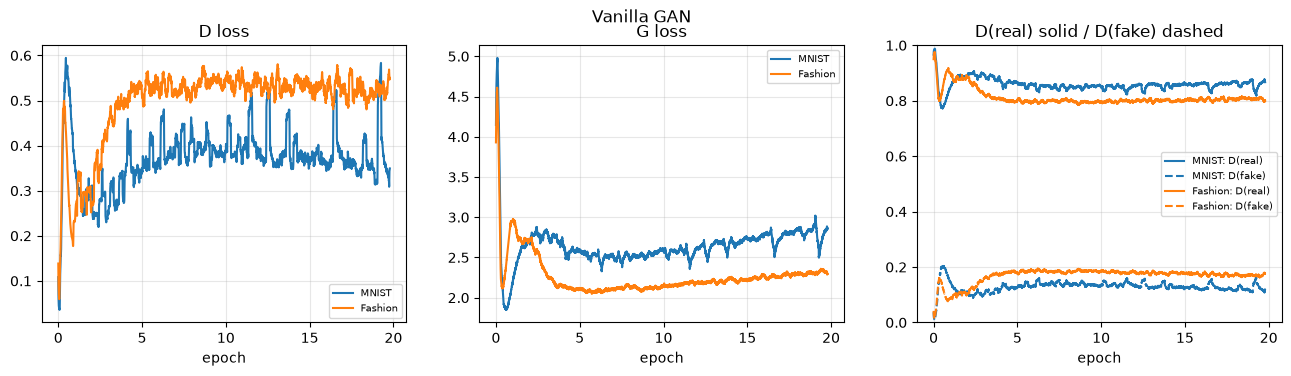

In [11]:
plot_training({'MNIST': log_mnist, 'Fashion': log_fashion}, 'Vanilla GAN')

## 11. PROGRESS DURING TRAINING (SAME NOISE EVERY TIME) → MODE COLLAPSE CHECK
Each grid = the **same 64 noise vectors** at a different epoch. **Mode collapse** would show as many **identical-looking** samples, or only one or two classes.

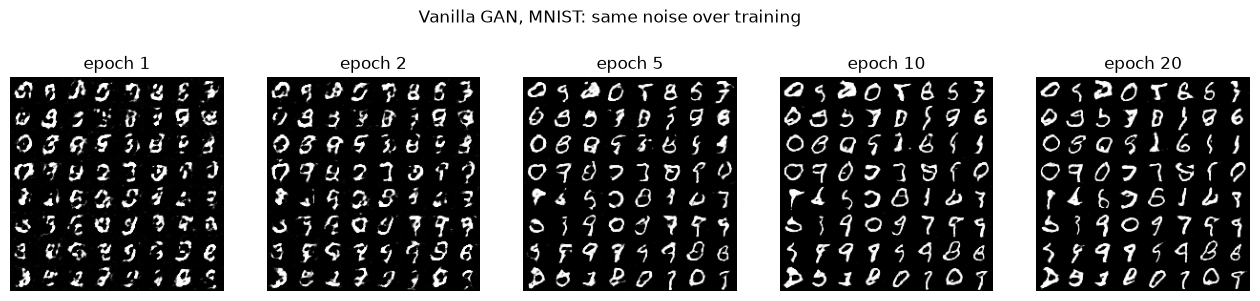

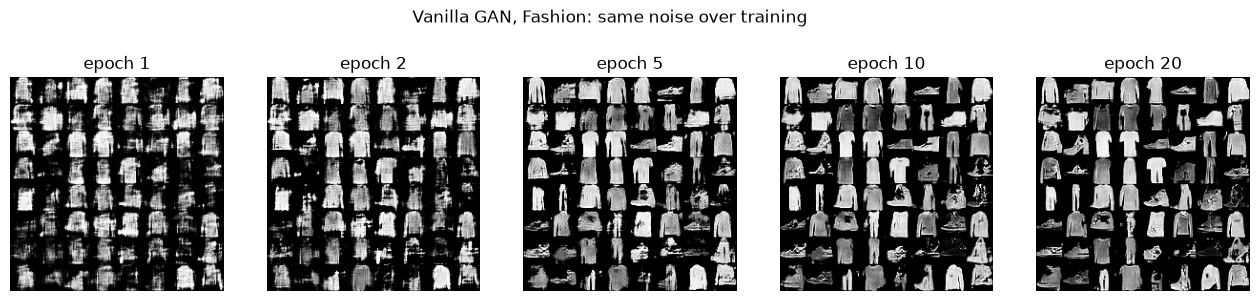

In [12]:
plot_progress(snaps_mnist, 'Vanilla GAN, MNIST: same noise over training')
plot_progress(snaps_fashion, 'Vanilla GAN, Fashion: same noise over training')

## 12. FINAL SAMPLES + SCORES
Left: 100 new samples. Right: **how often the judge sees each class** among 5,000 samples. **A flat bar chart = no mode collapse.**

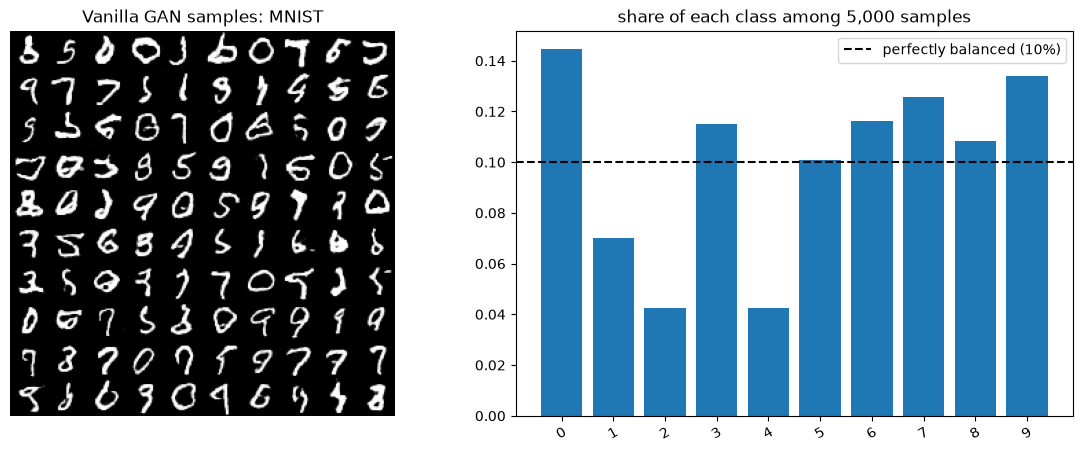

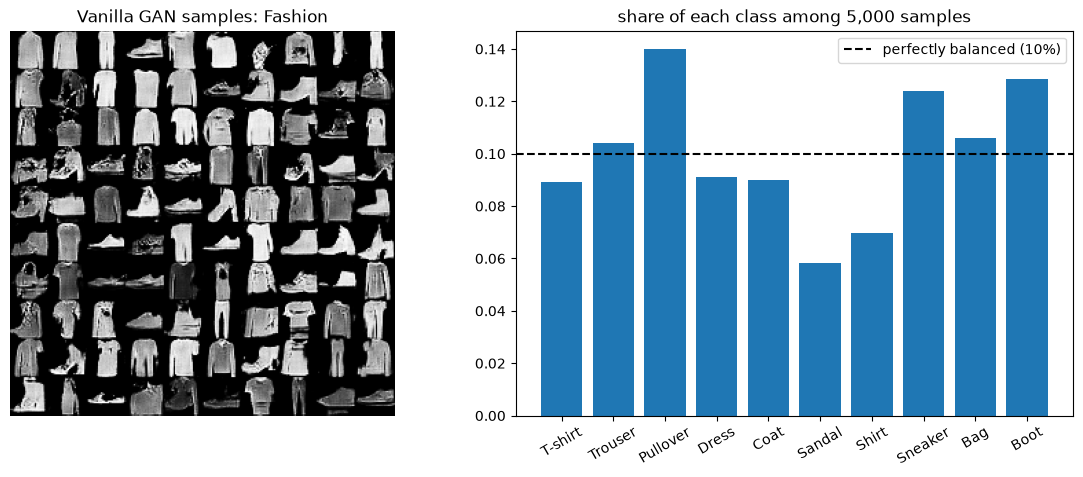

,class coverage,confidence,diversity,label accuracy
REAL MNIST,0.999,0.981,1.000,0.983
REAL Fashion,0.995,0.900,1.000,0.896
"vanilla GAN, MNIST",0.971,0.865,1.063,NaN
"vanilla GAN, Fashion",0.987,0.769,1.062,NaN


In [13]:
scores = {}   # all scores of all GANs, collected for the final table
for name, G, data in [('MNIST', G_mnist, mnist), ('Fashion', G_fashion, fashion)]:
    torch.manual_seed(0)
    samples = generate(G, torch.randn(5000, NOISE, device=device))
    result, share = judge(samples, data)
    scores[f'vanilla GAN, {name}'] = result

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 1.3]})
    show_grid(samples[:100], 10, axes[0], f'Vanilla GAN samples: {name}')
    axes[1].bar(data['classes'], share.numpy())
    axes[1].axhline(0.1, color='k', ls='--', label='perfectly balanced (10%)')
    axes[1].set_title('share of each class among 5,000 samples'); axes[1].tick_params(axis='x', rotation=30); axes[1].legend()
    plt.show()

score_table({**{f'REAL {n}': d['real_scores'] for n, d in [('MNIST', mnist), ('Fashion', fashion)]}, **scores})

## RESULT 1: VANILLA GAN WORKS AND STAYS STABLE; MILD CLASS IMBALANCE ON MNIST

| | class coverage | confidence | diversity |
|---|---|---|---|
| real MNIST | 0.999 | 0.981 | 1.00 |
| **vanilla GAN, MNIST** | 0.971 | 0.865 | 1.06 |
| real Fashion | 0.995 | 0.900 | 1.00 |
| **vanilla GAN, Fashion** | 0.987 | 0.769 | 1.06 |

**STABILITY: GOOD.** After ~3 epochs all curves go **flat**: D(real) ≈ 0.85 / 0.80, D(fake) ≈ 0.13 / 0.18 (MNIST / Fashion). D is ahead but never wins completely, so G keeps getting a useful signal. MNIST shows **small spikes** in D loss: short moments where G found a trick and D had to catch up. Normal GAN behaviour, it recovers every time.

**PROGRESS:** epoch 1–2 = blotches with the right overall layout → epoch 5 = recognizable digits and clothes → epochs 10–20 = sharper details.

**MODE COLLAPSE: NONE, BUT SOME IMBALANCE.**
- All 10 classes appear, and the fixed-noise grids stay varied over training.
- On MNIST the classes are **not equally common**: "0" 14.5%, "2" and "4" only ~4%. G prefers "easy" shapes. This is a **mild, partial** form of mode collapse.

**QUALITY:** the judge is **less sure** than on real images (0.87 vs 0.98 MNIST, 0.77 vs 0.90 Fashion): many samples are **malformed or in-between** classes.
*Note:* diversity slightly **> 1** does not mean "more varied than reality". Small artifacts and noise also increase pixel distance.

---
# PART 2: CONDITIONAL GAN (cGAN)

**Change:** both networks also get the **class label**.
- **G:** noise + label → "draw a *7*".
- **D:** image + label → "is this a **real 7**?". So G is punished for drawing the wrong class.

Snapshots now show **one class per row** (row 0 = class 0, …, row 9 = class 9).

## 13. TRAIN cGAN ON MNIST AND FASHION

In [14]:
torch.manual_seed(42)
cG_mnist, cD_mnist = Generator(n_classes=10), Discriminator(n_classes=10)
clog_mnist, csnaps_mnist = train_gan(cG_mnist, cD_mnist, mnist)

epoch  1   D loss 0.564   G loss 2.089   D(real) 0.78   D(fake) 0.20


epoch  5   D loss 0.697   G loss 1.665   D(real) 0.74   D(fake) 0.25


epoch 10   D loss 0.825   G loss 1.496   D(real) 0.70   D(fake) 0.28


epoch 15   D loss 0.832   G loss 1.519   D(real) 0.70   D(fake) 0.28


epoch 20   D loss 0.823   G loss 1.574   D(real) 0.70   D(fake) 0.27


In [15]:
torch.manual_seed(42)
cG_fashion, cD_fashion = Generator(n_classes=10), Discriminator(n_classes=10)
clog_fashion, csnaps_fashion = train_gan(cG_fashion, cD_fashion, fashion)

epoch  1   D loss 0.600   G loss 1.995   D(real) 0.77   D(fake) 0.20


epoch  5   D loss 0.972   G loss 1.225   D(real) 0.64   D(fake) 0.33


epoch 10   D loss 1.065   G loss 1.143   D(real) 0.62   D(fake) 0.36


epoch 15   D loss 1.036   G loss 1.202   D(real) 0.63   D(fake) 0.34


epoch 20   D loss 1.001   G loss 1.260   D(real) 0.64   D(fake) 0.33


## 14. cGAN: STABILITY, PROGRESS, SAMPLES PER CLASS

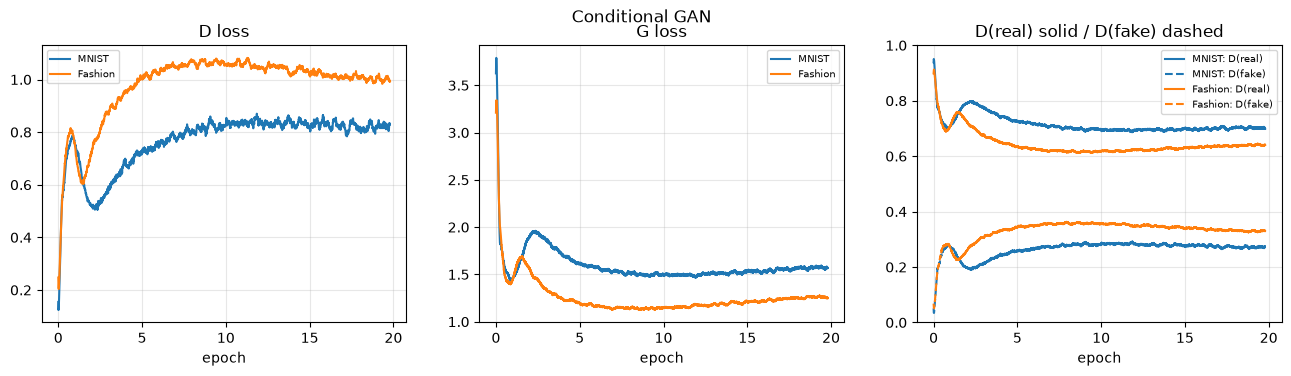

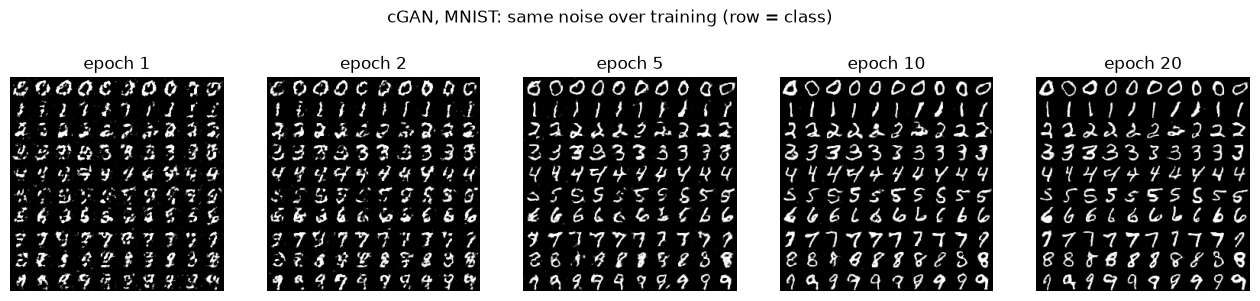

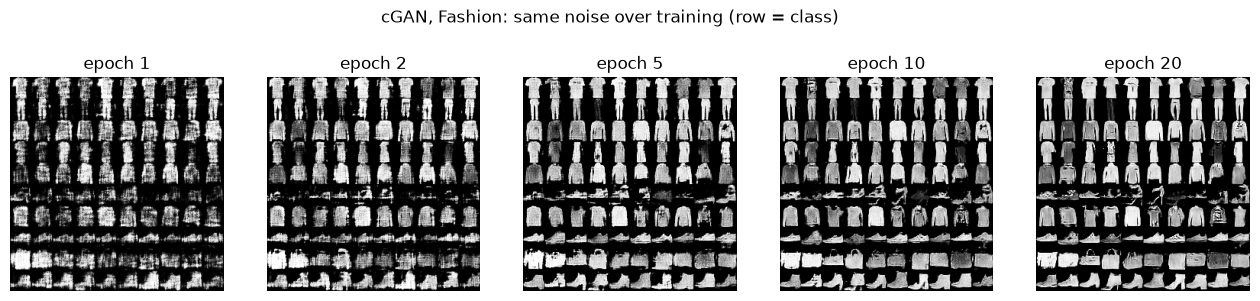

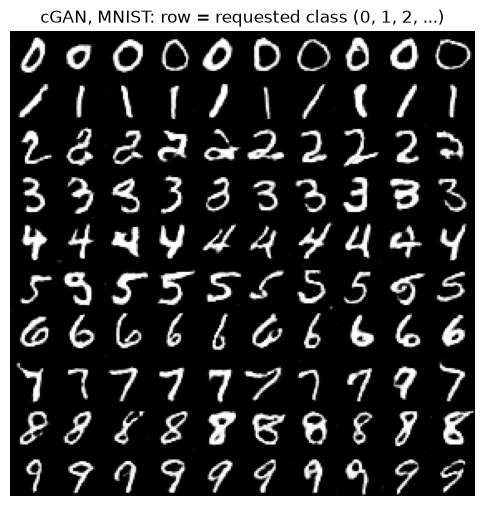

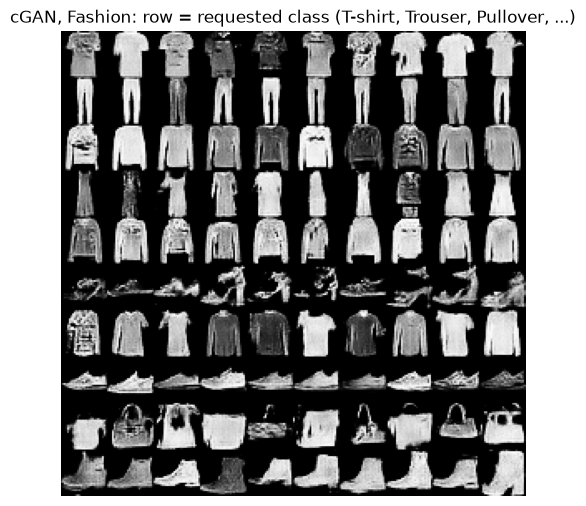

,class coverage,confidence,diversity,label accuracy
"vanilla GAN, MNIST",0.971,0.865,1.063,NaN
"vanilla GAN, Fashion",0.987,0.769,1.062,NaN
"cGAN, MNIST",1.000,0.988,1.019,0.989
"cGAN, Fashion",0.998,0.895,0.998,0.911


In [16]:
plot_training({'MNIST': clog_mnist, 'Fashion': clog_fashion}, 'Conditional GAN')
plot_progress(csnaps_mnist, 'cGAN, MNIST: same noise over training (row = class)', n=100, nrow=10)
plot_progress(csnaps_fashion, 'cGAN, Fashion: same noise over training (row = class)', n=100, nrow=10)

requested = torch.arange(10).repeat_interleave(500)           # 500 samples of every class
for name, G, data in [('MNIST', cG_mnist, mnist), ('Fashion', cG_fashion, fashion)]:
    torch.manual_seed(0)
    samples = generate(G, torch.randn(5000, NOISE, device=device), requested.to(device))
    scores[f'cGAN, {name}'] = judge(samples, data, requested=requested)[0]
    grid = torch.cat([samples[requested == c][:10] for c in range(10)])   # row c = class c
    fig, ax = plt.subplots(figsize=(6, 6.4))
    show_grid(grid, 10, ax, f'cGAN, {name}: row = requested class ({", ".join(data["classes"][:3])}, ...)')
    plt.show()

score_table(scores)

## RESULT 2: THE LABEL HELPS A LOT: cGAN IS ALMOST AS GOOD AS REAL DATA

| | class coverage | confidence | diversity | **label accuracy** |
|---|---|---|---|---|
| real MNIST | 0.999 | 0.981 | 1.00 | 0.983 |
| **cGAN, MNIST** | **1.000** | **0.988** | 1.02 | **0.989** |
| real Fashion | 0.995 | 0.900 | 1.00 | 0.896 |
| **cGAN, Fashion** | **0.998** | **0.895** | 1.00 | **0.911** |

- **DRAWS ON REQUEST:** the judge recognizes the requested class in **98.9% (MNIST)** and **91.1% (Fashion)** of samples, as often as for real test images.
- **QUALITY ≈ REAL:** confidence 0.988 / 0.895 vs 0.981 / 0.900 for real data (vanilla: 0.865 / 0.769).
- **NO MODE COLLAPSE:** classes are balanced by construction, and diversity inside each class **≈ 1** (different thickness, slant, styles; shirts with different prints, different bags).
- **WHY BETTER:** the label tells G *what* to draw, so it no longer has to decide that itself, and D checks **"is this a real *7*?"**, which is a stricter and more informative signal.
- The game is **more balanced** than vanilla: D(real) ≈ 0.70 / 0.64, D(fake) ≈ 0.27 / 0.33. D has a harder job, G gets more useful gradients.

---
# PART 3: BETTER DISCRIMINATORS FOR THE cGAN

Both are applied **on top of the cGAN** and compared with it (= "before").

**PatchGAN:** D outputs a **7×7 grid of verdicts**, each judging one **local patch** (≈ 18×18 px) instead of the whole image.
→ G is pushed to make **every region** look real: sharper strokes and textures.

**Feature matching** (Salimans et al., 2016): G no longer tries to make D say "real". Instead it makes the **average features** D extracts from fakes **match those of real images**.
→ a softer, more stable target for G; known to **reduce mode collapse**, sometimes at the cost of sharpness.

## 15. TRAIN cGAN + PATCHGAN (BOTH DATASETS)

In [17]:
torch.manual_seed(42)
pG_mnist, pD_mnist = Generator(n_classes=10), Discriminator(n_classes=10, patch=True)
plog_mnist, psnaps_mnist = train_gan(pG_mnist, pD_mnist, mnist)

epoch  1   D loss 0.981   G loss 1.132   D(real) 0.63   D(fake) 0.36


epoch  5   D loss 1.173   G loss 0.922   D(real) 0.57   D(fake) 0.42


epoch 10   D loss 1.262   G loss 0.858   D(real) 0.55   D(fake) 0.45


epoch 15   D loss 1.275   G loss 0.847   D(real) 0.55   D(fake) 0.45


epoch 20   D loss 1.271   G loss 0.856   D(real) 0.55   D(fake) 0.45


In [18]:
torch.manual_seed(42)
pG_fashion, pD_fashion = Generator(n_classes=10), Discriminator(n_classes=10, patch=True)
plog_fashion, psnaps_fashion = train_gan(pG_fashion, pD_fashion, fashion)

epoch  1   D loss 1.115   G loss 0.966   D(real) 0.59   D(fake) 0.40


epoch  5   D loss 1.241   G loss 0.841   D(real) 0.55   D(fake) 0.45


epoch 10   D loss 1.267   G loss 0.832   D(real) 0.54   D(fake) 0.45


epoch 15   D loss 1.275   G loss 0.832   D(real) 0.54   D(fake) 0.45


epoch 20   D loss 1.274   G loss 0.839   D(real) 0.54   D(fake) 0.45


## 16. TRAIN cGAN + FEATURE MATCHING (BOTH DATASETS)
Same as the cGAN, only `feature_matching=True` (the G loss changes).

In [19]:
torch.manual_seed(42)
fG_mnist, fD_mnist = Generator(n_classes=10), Discriminator(n_classes=10)
flog_mnist, fsnaps_mnist = train_gan(fG_mnist, fD_mnist, mnist, feature_matching=True)

epoch  1   D loss 0.262   G loss 0.024   D(real) 0.89   D(fake) 0.10


epoch  5   D loss 0.120   G loss 0.005   D(real) 0.95   D(fake) 0.04


epoch 10   D loss 0.135   G loss 0.004   D(real) 0.95   D(fake) 0.04


epoch 15   D loss 0.137   G loss 0.004   D(real) 0.95   D(fake) 0.05


epoch 20   D loss 0.136   G loss 0.004   D(real) 0.94   D(fake) 0.05


In [20]:
torch.manual_seed(42)
fG_fashion, fD_fashion = Generator(n_classes=10), Discriminator(n_classes=10)
flog_fashion, fsnaps_fashion = train_gan(fG_fashion, fD_fashion, fashion, feature_matching=True)

epoch  1   D loss 0.290   G loss 0.013   D(real) 0.88   D(fake) 0.11


epoch  5   D loss 0.163   G loss 0.004   D(real) 0.94   D(fake) 0.06


epoch 10   D loss 0.160   G loss 0.004   D(real) 0.94   D(fake) 0.06


epoch 15   D loss 0.160   G loss 0.004   D(real) 0.94   D(fake) 0.05


epoch 20   D loss 0.138   G loss 0.004   D(real) 0.95   D(fake) 0.04


## 17. COMPARE: BEFORE (cGAN) vs PATCHGAN vs FEATURE MATCHING
1. **Training curves** of the three variants.
2. **Samples side by side**: same noise, same labels (row = class).
3. **Scores table** for every GAN in this notebook.

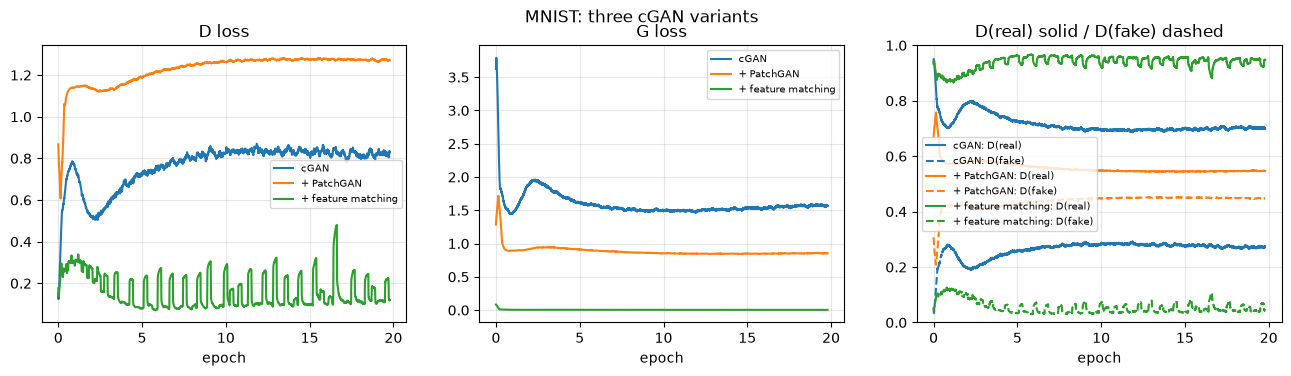

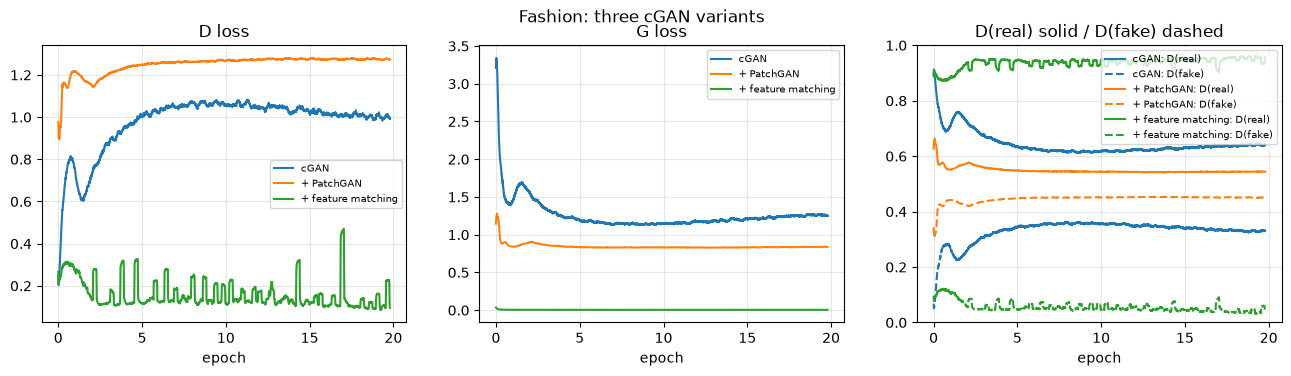

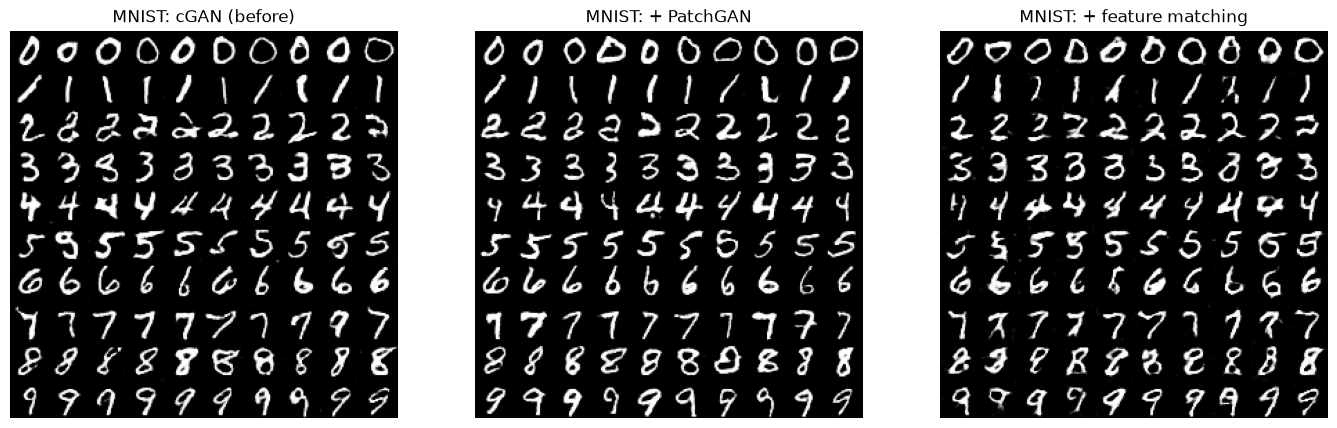

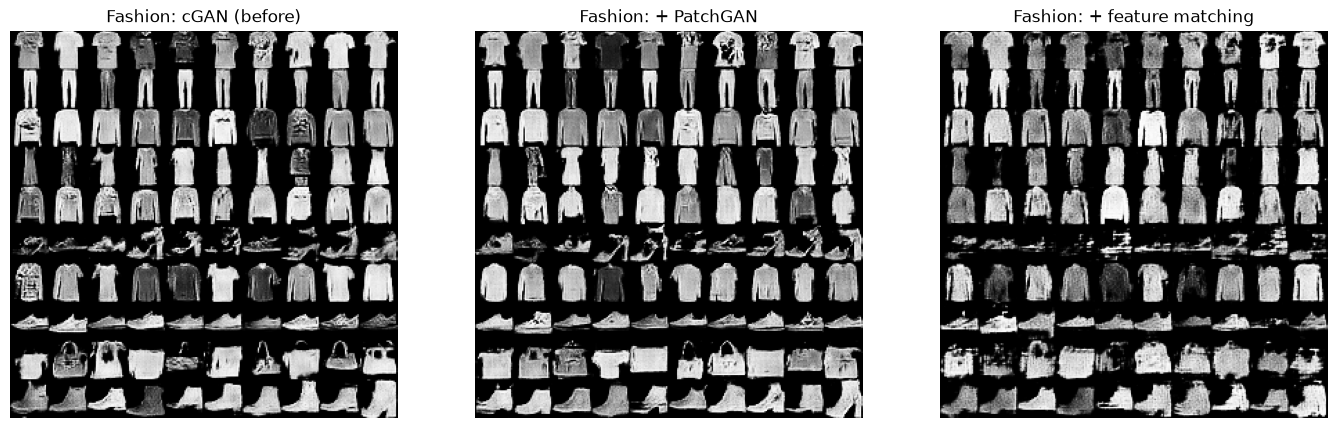

,class coverage,confidence,diversity,label accuracy
REAL MNIST,0.999,0.981,1.000,0.983
REAL Fashion,0.995,0.900,1.000,0.896
"vanilla GAN, MNIST",0.971,0.865,1.063,NaN
"vanilla GAN, Fashion",0.987,0.769,1.062,NaN
"cGAN, MNIST",1.000,0.988,1.019,0.989
"cGAN, Fashion",0.998,0.895,0.998,0.911
"PatchGAN, MNIST",1.000,0.987,1.026,0.989
"feature matching, MNIST",1.000,0.967,0.992,0.960
"PatchGAN, Fashion",0.997,0.899,1.009,0.909
"feature matching, Fashion",0.995,0.856,0.969,0.868


In [21]:
plot_training({'cGAN': clog_mnist, '+ PatchGAN': plog_mnist, '+ feature matching': flog_mnist}, 'MNIST: three cGAN variants')
plot_training({'cGAN': clog_fashion, '+ PatchGAN': plog_fashion, '+ feature matching': flog_fashion}, 'Fashion: three cGAN variants')

for name, data, variants in [
        ('MNIST', mnist, {'cGAN (before)': cG_mnist, '+ PatchGAN': pG_mnist, '+ feature matching': fG_mnist}),
        ('Fashion', fashion, {'cGAN (before)': cG_fashion, '+ PatchGAN': pG_fashion, '+ feature matching': fG_fashion})]:
    fig, axes = plt.subplots(1, 3, figsize=(17, 6))
    for ax, (label, G) in zip(axes, variants.items()):
        torch.manual_seed(0)
        samples = generate(G, torch.randn(5000, NOISE, device=device), requested.to(device))
        if label != 'cGAN (before)':
            scores[f'{label[2:]}, {name}'] = judge(samples, data, requested=requested)[0]
        grid = torch.cat([samples[requested == c][:10] for c in range(10)])
        show_grid(grid, 10, ax, f'{name}: {label}')
    plt.show()

score_table({**{f'REAL {n}': d['real_scores'] for n, d in [('MNIST', mnist), ('Fashion', fashion)]}, **scores})

## RESULT 3: PATCHGAN ≈ SAME AS cGAN; FEATURE MATCHING IS WORSE HERE

| | confidence | diversity | label accuracy |
|---|---|---|---|
| **cGAN (before), MNIST** | 0.988 | 1.02 | 0.989 |
| + PatchGAN, MNIST | 0.987 | 1.03 | 0.989 |
| + feature matching, MNIST | 0.967 | 0.99 | 0.960 |
| **cGAN (before), Fashion** | 0.895 | 1.00 | 0.911 |
| + PatchGAN, Fashion | 0.899 | 1.01 | 0.909 |
| + feature matching, Fashion | 0.856 | 0.97 | 0.868 |

**PATCHGAN: NO CLEAR GAIN.**
- Scores and pictures are **practically the same** as the cGAN (differences ≤ 0.005).
- **Why:** on 28×28 images each patch already covers **≈ 18×18 px**, so most of the image. The "local" detective is **almost global**. PatchGAN shines on **large** images (e.g. 256×256) with fine textures.
- The game is the **closest** of all: D(real) 0.55 / D(fake) 0.45. Patch by patch, D can barely tell real from fake.

**FEATURE MATCHING: WORSE QUALITY, NO DIVERSITY GAIN.**
- Visibly **noisier**: speckles, smeared sandals and bags. Confidence and label accuracy **drop** (MNIST 0.989 → 0.960, Fashion 0.911 → 0.868).
- G loss falls to **≈ 0.004**: the **average** features of fakes match real ones almost perfectly, but **individual** images can still look wrong. Matching an average is a weaker demand than "fool D on every image".
- D becomes **very confident** (D(fake) ≈ 0.05), because G no longer tries to fool it directly.
- Its main purpose, **fighting mode collapse**, had nothing to fix: the cGAN was already collapse-free.

**CONCLUSION:** for 28×28 MNIST / Fashion, the **plain cGAN** is the best trade-off. The two "advanced" discriminators either change nothing (PatchGAN) or trade sharpness for stability that was not needed (feature matching).
**Could improve:** a smaller PatchGAN receptive field, feature matching **combined** with the normal G loss, or larger, more textured images.